# Pure diffusion: solar-ring age distribution
Analyze `diffusion.cpp` with 10,000 protons injected at the origin, initial total energies 10–10^6 GeV, and propagation to 10^8 yr. There is no wind, cooling, fragmentation, or escape boundary.

The binary file contains native-endian float64 pairs `(total energy [GeV], elapsed time [yr])`. Each step endpoint inside the solar ring contributes a sample, including repeated visits. This is an occupancy-sample age distribution, not a first-arrival distribution. No particle ID is recorded, so independent-sample Poisson errors are not assigned.


In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

# Run from age_dist/ or the project directory. Edit these for another run.
data_dir = Path('.')
if not (data_dir / 'proton_earth_t1e8.bin').exists():
    data_dir = Path('age_dist')
file = data_dir / 'proton_earth_t1e8.bin'
N_particles = 10000
E_min, E_max = 10.0, 1e6  # total proton energy, GeV
t_end = 1e8              # yr
R_earth = 8000.0         # pc
m_p = 0.938272           # rest energy, GeV
c_pc_yr = 0.30660139

arrivals = np.fromfile(file, dtype='=f8').reshape(-1, 2)
E_arr, time_arr = arrivals.T
if len(arrivals) == 0:
    raise ValueError('No solar-ring samples in the selected file.')
if not np.all(np.isfinite(arrivals)) or np.any(time_arr <= 0) or np.any(time_arr > t_end):
    raise ValueError('Invalid records or propagation time does not match the run.')
print('File:', file)
print('Step samples:', len(arrivals))
print('Total energy min / median / max [GeV]:', np.percentile(E_arr, [0, 50, 100]))
print('Age min / median / max [Myr]:', np.percentile(time_arr/1e6, [0, 50, 100]))


File: proton_earth_t1e8.bin
Step samples: 57368
Total energy min / median / max [GeV]: [1.01742112e+01 1.35304777e+04 9.98849255e+05]
Age min / median / max [Myr]: [ 0.26937053 18.86798921 99.90920306]


## Diffusion reference and sampling weights
For one proton injected at the origin, the diffusion-limit probability density is
$$G(r,t;E)=(4\pi D(E)t)^{-3/2}\exp[-r^2/(4D(E)t)],\quad D=c\lambda/3.$$
The detector is a torus with major radius $R_\oplus$ and tube radius $\lambda(E)$. Its volume is $V=2\pi^2R_\oplus\lambda^2$. Approximating the density throughout the tube by $G(R_\oplus,t;E)$ gives
$$\frac{dN_{\rm sample}}{dt}\simeq\sum_{i=1}^{N}\frac{V_i}{\Delta t_i}G(R_\oplus,t;E_i),\qquad\Delta t_i=\lambda_i/(2c).$$
This includes the actual deterministic injection grid, the energy-dependent detector volume, and the frequency of step sampling. It is a small-tube, diffusion-limit approximation, not an exact finite-step prediction. The shortened last step is neglected in this reference.


In [2]:
E_start = np.logspace(np.log10(E_min), np.log10(E_max), N_particles)
rigidity = np.sqrt((E_start-m_p)*(E_start+m_p))  # GV for protons
lambda_start = 2.0*(rigidity/10.0)**(1/3)         # pc
dt_start = lambda_start/(2*c_pc_yr)              # yr
D_start = c_pc_yr*lambda_start/3                 # pc^2/yr
volume = 2*np.pi**2*R_earth*lambda_start**2       # pc^3
sample_weight = volume/dt_start                 # pc^3/yr
print('D range [pc^2/yr]:', D_start.min(), D_start.max())
print('Fixed-energy dN/dln(t) peak times [Myr], low/high E:',
      (R_earth**2/(2*D_start[[0, -1]]))/1e6)

# Use total energy for energy bins. Here t denotes age, not kinetic energy.
energy_bins = np.logspace(np.log10(E_min*0.999), np.log10(E_max*1.001), 26)
energy_centers = np.sqrt(energy_bins[:-1]*energy_bins[1:])
dlnE = np.diff(np.log(energy_bins))
# Cover every observed age. Keep the lower bound no later than 10^5 yr.
t_min = min(1e5, time_arr.min()*0.99)
time_bins = np.logspace(np.log10(t_min), np.log10(t_end), 41)
time_bins[-1] = t_end
time_centers = np.sqrt(time_bins[:-1]*time_bins[1:])
dt_bins = np.diff(time_bins)
dlnt = np.diff(np.log(time_bins))

# histogram2d counts samples in each (energy, age) bin; rows are energy bins.
counts_2d = np.histogram2d(E_arr, time_arr, bins=[energy_bins, time_bins])[0]
counts_energy = np.sum(counts_2d, axis=1)
counts_time = np.sum(counts_2d, axis=0)


D range [pc^2/yr]: 0.20409991186262055 9.487450587959652
Fixed-energy dN/dln(t) peak times [Myr], low/high E: [156.78595698   3.37287659]


In [3]:
# Integrate the expected sample rate within each time bin, rather than
# evaluating a potentially curved distribution only at the bin center.
# Work in ln(t): dt = t*dln(t). The explicit trapezoid sum below integrates
# rate(t)*t over ln(t); no fitting or rescaling to observed counts is applied.
theory_2d = np.zeros(counts_2d.shape)
for j in range(len(time_centers)):
    logt_grid = np.linspace(np.log(time_bins[j]), np.log(time_bins[j+1]), 33)
    t_grid = np.exp(logt_grid)
    rate_grid = np.zeros((len(E_start), len(t_grid)))
    for k in range(len(t_grid)):
        t = t_grid[k]
        G = np.exp(-R_earth**2/(4*D_start*t))/(4*np.pi*D_start*t)**1.5
        rate_grid[:, k] = sample_weight*G*t
    contributions = (rate_grid[:, 1:] + rate_grid[:, :-1])/2
    expected_per_particle = np.sum(contributions*np.diff(logt_grid), axis=1)
    theory_2d[:, j] = np.histogram(E_start, bins=energy_bins, weights=expected_per_particle)[0]
theory_energy = np.sum(theory_2d, axis=1)
theory_time = np.sum(theory_2d, axis=0)
print('Observed samples in plotted bins:', int(np.sum(counts_2d)))
print('Diffusion-limit expected samples in plotted bins:', np.sum(theory_2d))


Observed samples in plotted bins: 57368
Diffusion-limit expected samples in plotted bins: 56129.650326124276


## Energy spectrum and age distributions
Divide by the relevant bin width to distinguish $dN/dt$ from $dN/d\ln t=t\,dN/dt$. A logarithmic x axis alone does not change the normalization. Energy counts represent step samples rather than a physical flux. The reference covers the same plotted time interval as the data.


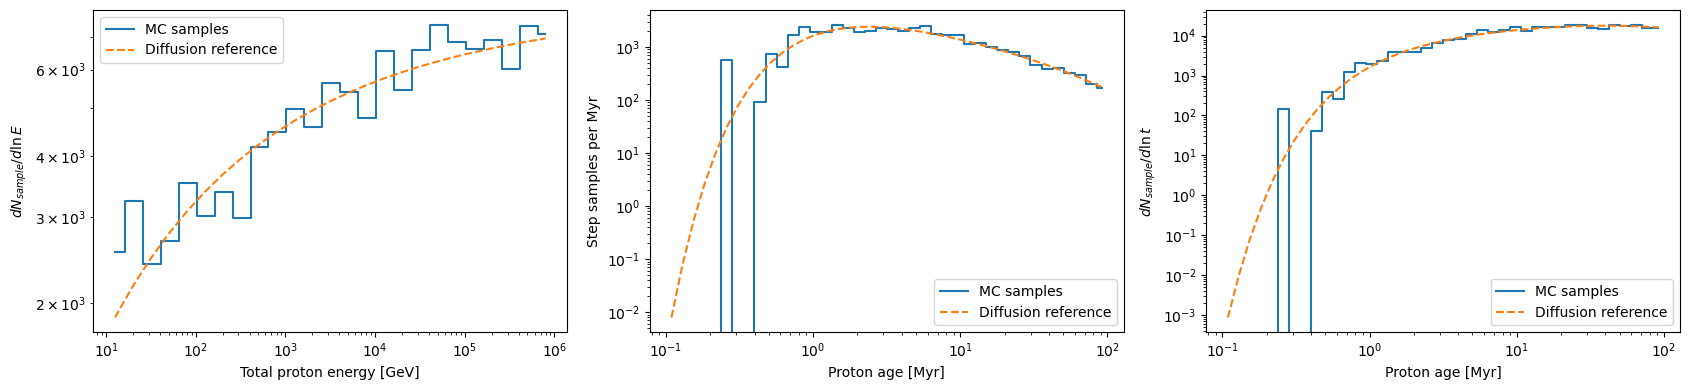

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
axes[0].step(energy_centers, counts_energy/dlnE, where='mid', label='MC samples')
axes[0].plot(energy_centers, theory_energy/dlnE, '--', label='Diffusion reference')
axes[0].set_xlabel('Total proton energy [GeV]')
axes[0].set_ylabel(r'$dN_{sample}/d\ln E$')
axes[1].step(time_centers/1e6, counts_time/(dt_bins/1e6), where='mid', label='MC samples')
axes[1].plot(time_centers/1e6, theory_time/(dt_bins/1e6), '--', label='Diffusion reference')
axes[1].set_xlabel('Proton age [Myr]')
axes[1].set_ylabel('Step samples per Myr')
axes[2].step(time_centers/1e6, counts_time/dlnt, where='mid', label='MC samples')
axes[2].plot(time_centers/1e6, theory_time/dlnt, '--', label='Diffusion reference')
axes[2].set_xlabel('Proton age [Myr]')
axes[2].set_ylabel(r'$dN_{sample}/d\ln t$')
for i in range(3):
    axes[i].set_xscale('log')
    axes[i].set_yscale('log')
    axes[i].legend()
fig.tight_layout()
plt.show()


## Age distribution in separate energy bands
At fixed energy, $dN_{sample}/d\ln t\propto t^{-1/2}\exp[-R_\oplus^2/(4Dt)]$, peaking at $R_\oplus^2/(2D)$. The total distribution mixes energies with different peak ages and sampling weights. A peak later than the run end is not fully observed.


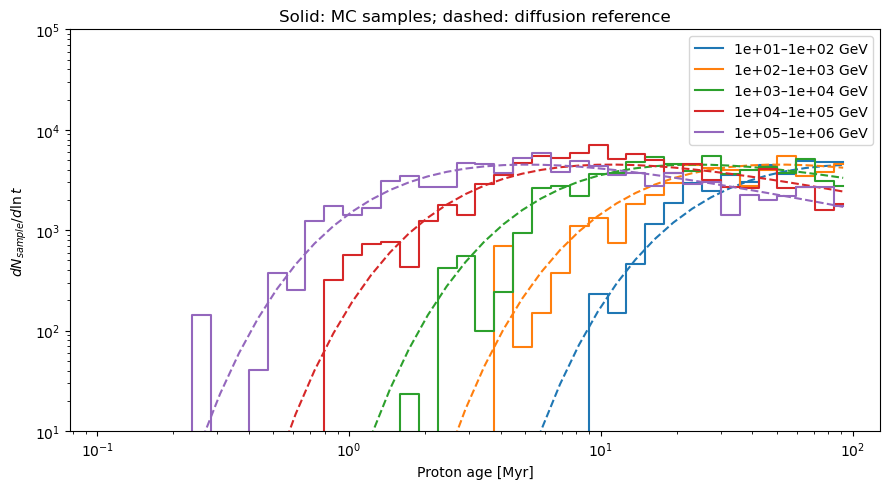

In [5]:
band_edges = np.array([10.0*0.999, 1e2, 1e3, 1e4, 1e5, 1e6*1.001])
fig, ax = plt.subplots(figsize=(9, 5))
for i in range(len(band_edges)-1):
    low, high = band_edges[i], band_edges[i+1]
    selected = (E_arr >= low) & (E_arr < high)
    observed = np.histogram(time_arr[selected], bins=time_bins)[0]
    selected_initial = (E_start >= low) & (E_start < high)
    expected = np.zeros(len(time_centers))
    # Reuse the same direct quadrature for each broad energy band.
    for j in range(len(time_centers)):
        logt_grid = np.linspace(np.log(time_bins[j]), np.log(time_bins[j+1]), 33)
        rate = np.zeros(len(logt_grid))
        for k in range(len(logt_grid)):
            t = np.exp(logt_grid[k])
            D = D_start[selected_initial]
            G = np.exp(-R_earth**2/(4*D*t))/(4*np.pi*D*t)**1.5
            rate[k] = np.sum(sample_weight[selected_initial]*G)*t
        expected[j] = np.sum((rate[1:]+rate[:-1])/2*np.diff(logt_grid))
    line = ax.step(time_centers/1e6, observed/dlnt, where='mid',
                   label=f'{10**(i+1):.0e}–{10**(i+2):.0e} GeV')[0]
    ax.plot(time_centers/1e6, expected/dlnt, '--', color=line.get_color())
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlabel('Proton age [Myr]')
ax.set_ylabel(r'$dN_{sample}/d\ln t$')
ax.set_title('Solid: MC samples; dashed: diffusion reference')
ax.set_ylim(1e1,1e5)
ax.legend()
fig.tight_layout()
plt.show()


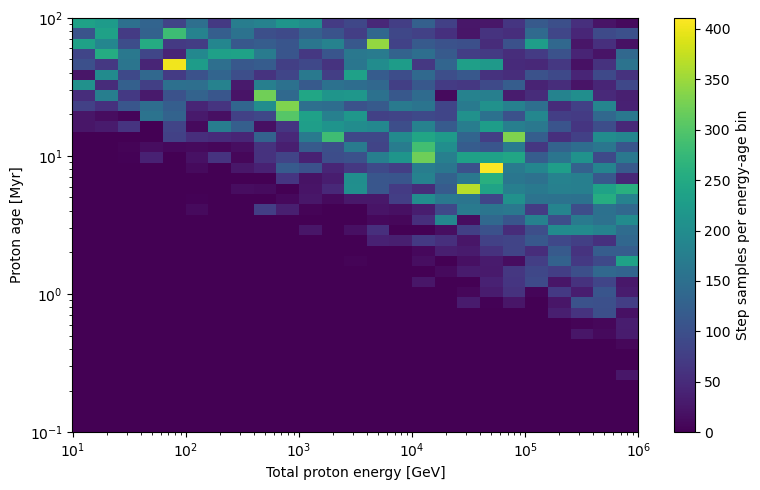

In [6]:
# Transpose so pcolormesh rows correspond to age and columns to energy.
fig, ax = plt.subplots(figsize=(8, 5))
image = ax.pcolormesh(energy_bins, time_bins/1e6, counts_2d.T, shading='auto')
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlabel('Total proton energy [GeV]')
ax.set_ylabel('Proton age [Myr]')
fig.colorbar(image, ax=ax, label='Step samples per energy-age bin')
fig.tight_layout()
plt.show()


## Interpretation limits
Repeated visits from a single proton are correlated. Differences from the reference include finite particle statistics, the finite-step walk, the small-tube approximation, and temporal bin integration. The plots are truncated at the configured run duration. No first-arrival probability or unique-particle count can be inferred simply by counting these records. No source-spectrum or detector-flux reweighting is applied.


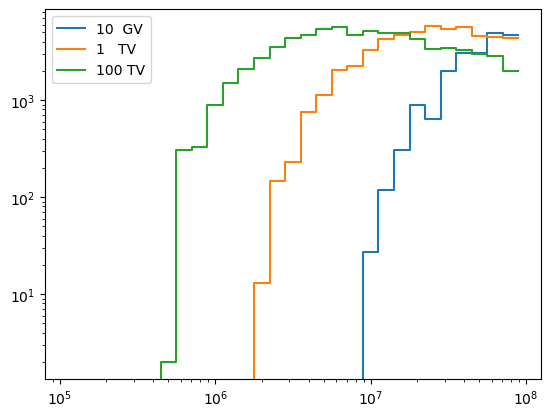

In [7]:
da_10GV = np.fromfile("proton_earth_t1e8_10GV.bin", dtype='=f8').reshape(-1, 2)
da_1TV = np.fromfile("proton_earth_t1e8_1TV.bin", dtype='=f8').reshape(-1, 2)
da_100TV = np.fromfile("proton_earth_t1e8_100TV.bin", dtype='=f8').reshape(-1, 2)

time_bins = np.logspace(5, 8, 31)
time_centers = np.sqrt(time_bins[:-1]*time_bins[1:])
dlnt = np.diff(np.log(time_bins))
age_10GV = np.histogram(da_10GV[:,1], bins = time_bins)[0]
age_1TV = np.histogram(da_1TV[:,1], bins = time_bins)[0]
age_100TV = np.histogram(da_100TV[:,1], bins = time_bins)[0]

plt.step(time_centers, age_10GV, label = "10  GV")
plt.step(time_centers, age_1TV, label = "1   TV")
plt.step(time_centers, age_100TV, label = "100 TV")

plt.xscale("log")
plt.yscale("log")
plt.legend()

np.float64(595664.0596813296)